# CO deposition experiments: surface diagnostics and CO flux into the ocean

Surface CO2, CO, CH4, H2O and temperature versus instellation for the Sun (3 Ga) and GJ 876, for three CO surface boundary conditions, plus the flux of CO into the ocean.

| Scenario | CO deposition velocity | CO surface source flux |
|---|---|---|
| baseline (saved sweep runs) | 1e-8 cm/s | 1e9 molecules/cm$^2$/s |
| `vdep0` | 0 | 0 |
| `vdep1.2e-4` (abiotic maximum) | 1.2e-4 cm/s | 0 |

**CO flux into the ocean** is the deposition flux, $F_\mathrm{dep} = v_\mathrm{dep}\, n_\mathrm{CO}$, with $n_\mathrm{CO}$ the CO number density in the lowest model layer (molecules/cm$^2$/s). The model's boundary condition is exactly this, so it is not a separate calculation. The *net* flux is $F_\mathrm{dep}$ minus the surface source flux (negative means the surface is a net CO source). For the global figure, the whole planet surface is assumed to be ocean, so it is an upper bound.

Marker key: filled = surface held at 288 K; open = 288 K not reachable (CO2 at its cap or maximum-greenhouse value); a cross marks a run whose CO2 coupling loop did not converge.

In [1]:
import json, glob, os, csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

K_B = 1.380649e-16                        # erg/K
AREA_CM2 = 4*np.pi*6.371e8**2             # planet surface area, cm^2 (Earth radius)
SEC_YR, N_A = 3.15576e7, 6.02214e23
SCEN = {'baseline': dict(label='baseline (vdep 1e-8, source 1e9)', vdep=1e-8, src=1e9, color='#7a7a7a', marker='s'),
        'vdep0': dict(label='vdep 0, source 0', vdep=0.0, src=0.0, color='#eb6834', marker='^'),
        'vdep1.2e-4': dict(label='vdep 1.2e-4, source 0', vdep=1.2e-4, src=0.0, color='#2a78d6', marker='o')}

def surface_density(meta):
    d = f"saved_inputs/{meta['run_id']}"; f = f"{d}/{meta['saved_inputs']['files']['atmosphere']}"
    names = open(f).readline().split(); row = np.loadtxt(f, skiprows=1, max_rows=1)   # lowest layer
    return float(row[names.index('den')])

rows = []
for p in sorted(glob.glob('saved_inputs/*/*_run.json')):
    m = json.load(open(p)); ce = m.get('co_experiment')
    if ce is None:
        if not m['photochem_steady'] or m.get('haze', {}).get('radius_is_photochem_default', True) is False: continue
        sc = 'baseline'
    else:
        sc = 'vdep0' if ce['CO_vdep_cm_s'] == 0 else 'vdep1.2e-4'
    s = SCEN[sc]; v = m['vmr']; n = surface_density(m)
    dep = s['vdep'] * n * v['CO']
    rows.append(dict(star=m['star'], S=m['S_Wm2'], scenario=sc, T=m['T_surf_K'], pCO2_bar=m['pCO2_bar'], P_total_bar=m['P_total_bar'],
                     CO2=v['CO2'], CO=v['CO'], CH4=v['CH4'], H2O=v['H2O'], H2=v['H2'], O2=v['O2'], n_surface=n,
                     CO_dep_flux=dep, CO_net_flux=dep - s['src'], at_288=abs(m['T_surf_K'] - 288.0) < 1.5,
                     coupling_converged=bool(m['coupling_converged']), run_id=m['run_id']))
rows.sort(key=lambda r: (r['star'], r['scenario'], -r['S']))
print(len(rows), 'runs:', {sc: sum(r['scenario']==sc for r in rows) for sc in SCEN})
print('not converged:', [(r['star'], r['S'], r['scenario']) for r in rows if not r['coupling_converged']])

111 runs: {'baseline': 37, 'vdep0': 37, 'vdep1.2e-4': 37}
not converged: [('Sun', 506.25, 'vdep1.2e-4'), ('Sun', 437.5, 'vdep1.2e-4')]


In [2]:
def series(star, sc, key):
    rr = [r for r in rows if r['star']==star and r['scenario']==sc]
    return rr, np.array([r['S'] for r in rr]), np.array([r[key] for r in rr], float)

def draw(ax, star, key, positive_only=False):
    for sc, s in SCEN.items():
        rr, x, y = series(star, sc, key)
        if positive_only: keep = y > 0; rr = [r for r, k in zip(rr, keep) if k]; x, y = x[keep], y[keep]
        if x.size == 0: continue
        ax.plot(x, y, '-', color=s['color'], lw=1.2, alpha=.8, zorder=2)
        for r, xi, yi in zip(rr, x, y):
            ax.plot(xi, yi, s['marker'], color=s['color'], mfc=s['color'] if r['at_288'] else 'white', ms=6, zorder=3)
            if not r['coupling_converged']: ax.plot(xi, yi, 'x', color='k', ms=9, mew=1.4, zorder=4)

legend_items = [Line2D([], [], color=s['color'], marker=s['marker'], lw=1.2, label=s['label']) for s in SCEN.values()] + \
    [Line2D([], [], color='gray', marker='o', ls='', mfc='gray', label='holds 288 K'),
     Line2D([], [], color='gray', marker='o', ls='', mfc='white', label='288 K not reached'),
     Line2D([], [], color='k', marker='x', ls='', label='coupling not converged')]
TITLE = {'Sun': 'Sun at 3 Ga', 'GJ876': 'GJ 876'}

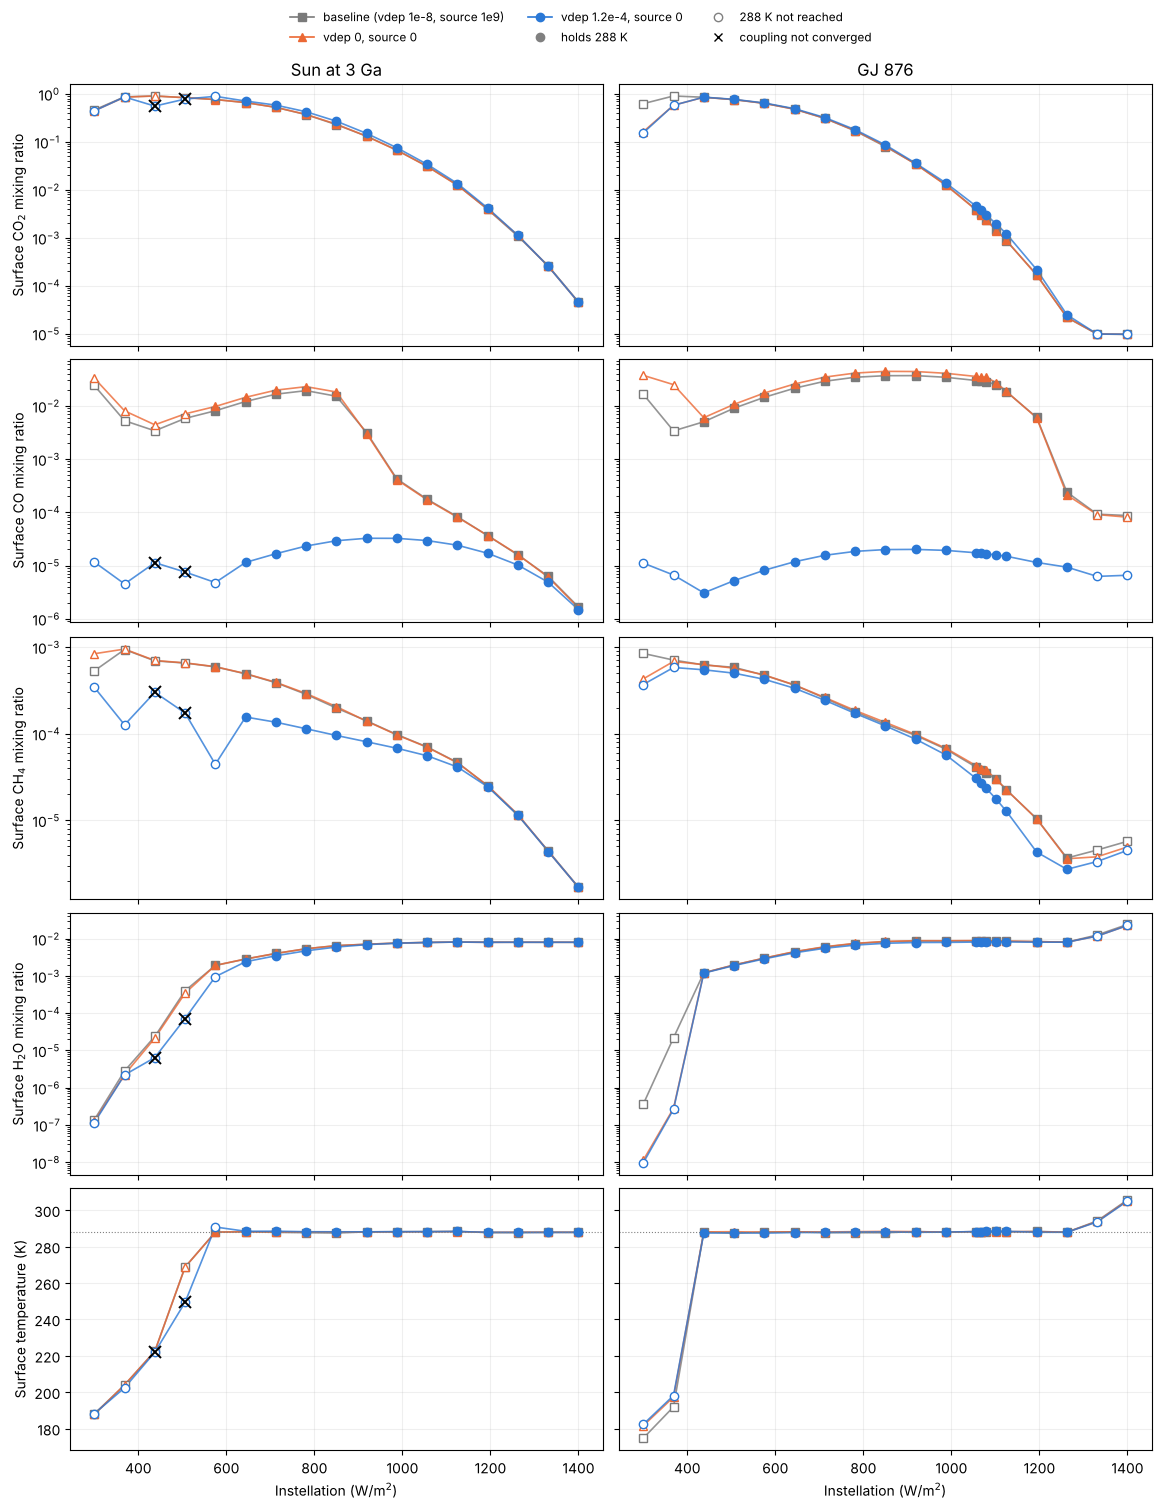

In [3]:
panels = [('CO2', 'Surface CO$_2$ mixing ratio', True), ('CO', 'Surface CO mixing ratio', True), ('CH4', 'Surface CH$_4$ mixing ratio', True),
          ('H2O', 'Surface H$_2$O mixing ratio', True), ('T', 'Surface temperature (K)', False)]
fig, axs = plt.subplots(len(panels), 2, figsize=(11.5, 15), sharex=True, sharey='row', constrained_layout=True)
for i, (key, lab, log) in enumerate(panels):
    for j, star in enumerate(['Sun', 'GJ876']):
        ax = axs[i, j]; draw(ax, star, key)
        if log: ax.set_yscale('log')
        if key == 'T': ax.axhline(288, color='gray', lw=.8, ls=':')
        if j == 0: ax.set_ylabel(lab)
        if i == 0: ax.set_title(TITLE[star])
        if i == len(panels) - 1: ax.set_xlabel('Instellation (W/m$^2$)')
        ax.grid(alpha=.2)
fig.legend(handles=legend_items, loc='outside upper center', ncol=3, fontsize=8.5, frameon=False)
plt.show()

**What the trends say** (read from the figures and `co_diagnostics_table.csv`):

- **CO is controlled by the deposition velocity, not by instellation alone.** With a vanishing sink (`vdep0`, source 0) CO is within 0.9-1.2 times the baseline (vdep 1e-8, source 1e9) in the runs that hold 288 K (largest increases near the CO maximum, peak 4.4e-2 for GJ 876 at 850 W/m$^2$); in the cold, CO2-capped runs the differences are larger (e.g. GJ 876 at 369 W/m$^2$, 2.5e-2 vs 3.4e-3) but the climate state also differs there. With the abiotic maximum (1.2e-4 cm/s) CO never exceeds 3.3e-5 (Sun) or 2.0e-5 (GJ 876): the broad 1e-2 plateau disappears.
- **Where CO is already low (hot, CO2-poor atmospheres: above ~1000 W/m$^2$ for the Sun, above ~1250 W/m$^2$ for GJ 876) the three scenarios converge**, because chemistry, not the surface, removes CO there.
- **CO2 and temperature barely respond.** Among runs that hold 288 K, the CO2 needed changes by at most about 20% (Sun) and 40% (GJ 876), mostly upward with the faster CO sink, and the surface temperature is the same by construction. Differences in temperature appear only where 288 K is unreachable, so they are not a CO effect.
- **CH4 does respond to the fast CO sink**: in the 288 K runs it falls to about 30% (Sun) and 40% (GJ 876) of the baseline at the strongest, while `vdep0` leaves CH4 within about 10% of the baseline.
- **H2O follows temperature**: it collapses below ~575 W/m$^2$ for the Sun and ~440 W/m$^2$ for GJ 876, where the surface can no longer be kept at 288 K.
- The cold, CO2-capped runs (open markers) carry the climate/photochemistry mismatch noted in the saved-inputs README; the two crossed Sun points (437.5 and 506.25 W/m$^2$, vdep 1.2e-4) did not converge and CO2/T there are not uniquely determined, although their CO is stable (about 1e-5).

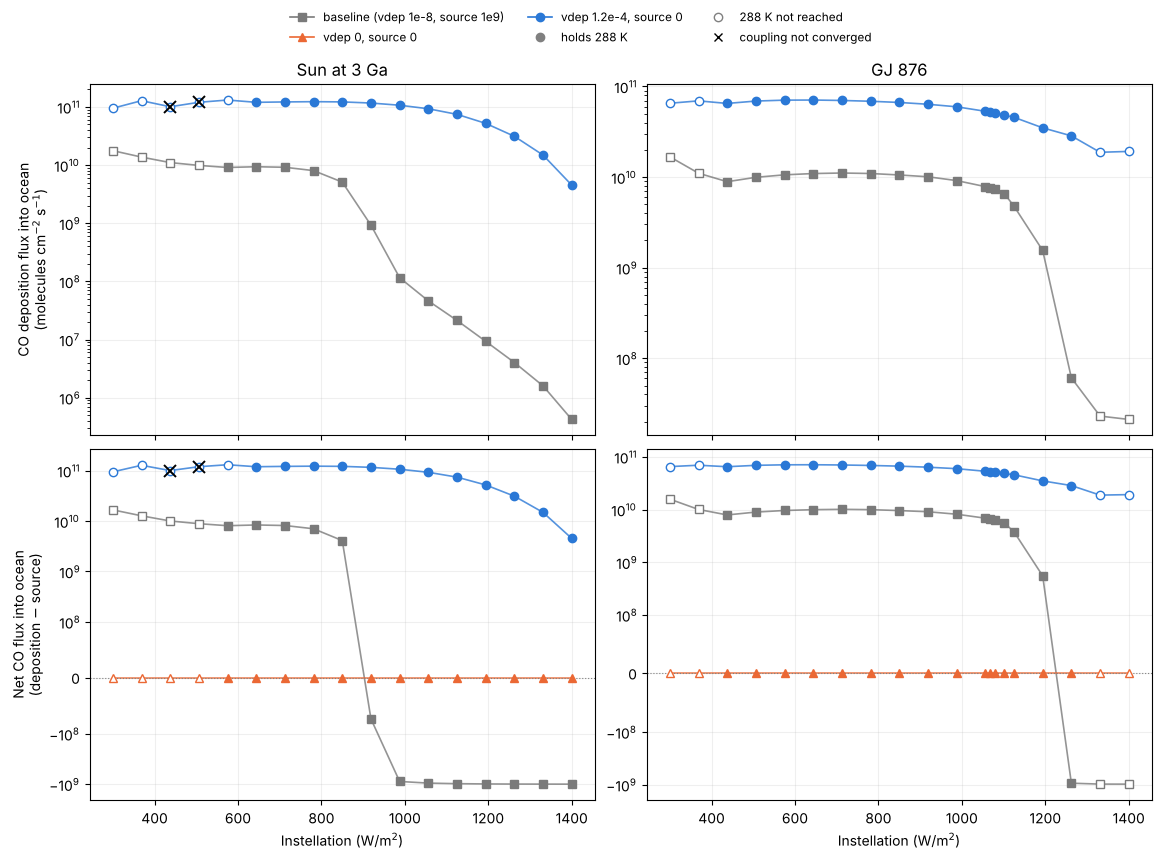

The vdep0 scenario has zero deposition flux by construction (not drawn on the log axis); its net flux is 0.


In [4]:
# CO flux into the ocean
fig, axs = plt.subplots(2, 2, figsize=(11.5, 8.5), sharex=True, constrained_layout=True)
for j, star in enumerate(['Sun', 'GJ876']):
    ax = axs[0, j]; draw(ax, star, 'CO_dep_flux', positive_only=True); ax.set_yscale('log'); ax.set_title(TITLE[star]); ax.grid(alpha=.2)
    if j == 0: ax.set_ylabel('CO deposition flux into ocean\n(molecules cm$^{-2}$ s$^{-1}$)')
    ax = axs[1, j]; draw(ax, star, 'CO_net_flux'); ax.set_yscale('symlog', linthresh=1e8); ax.axhline(0, color='gray', lw=.8, ls=':')
    ax.set_xlabel('Instellation (W/m$^2$)'); ax.grid(alpha=.2)
    if j == 0: ax.set_ylabel('Net CO flux into ocean\n(deposition $-$ source)')
fig.legend(handles=legend_items, loc='outside upper center', ncol=3, fontsize=8.5, frameon=False)
plt.show()
print('The vdep0 scenario has zero deposition flux by construction (not drawn on the log axis); its net flux is 0.')

**CO flux into the ocean.**

- With `vdep 1.2e-4` the deposition flux is large and nearly independent of instellation over a wide range: about 1e11 molecules/cm$^2$/s for the Sun (maximum 1.3e11 at 575 W/m$^2$, falling to 4.5e9 at 1400 W/m$^2$) and about 5-7e10 for GJ 876 (maximum 7.1e10 at 644 W/m$^2$, falling to 1.9e10 at the hot end). Because CO is held so low, the flux is set by how fast chemistry supplies CO, not by the surface sink; this is an interpretation, not tested separately here.
- The baseline flux (vdep 1e-8) is 1-2 orders of magnitude smaller and, unlike the fast-sink case, tracks the CO abundance, falling steeply as instellation rises once CO collapses (above ~850 W/m$^2$ for the Sun, above ~1125 W/m$^2$ for GJ 876).
- **Net flux** (deposition minus the 1e9 source): the baseline net flux changes sign near 920-990 W/m$^2$ for the Sun and 1200-1260 W/m$^2$ for GJ 876. At higher instellation the 1e9 source exceeds what the 1e-8 cm/s sink removes, so the surface is a net CO source; at lower instellation the ocean is a net CO sink. `vdep0` with zero source has no ocean flux at all, by construction.
- If the whole surface were ocean, the 1.2e-4 deposition flux corresponds to up to about 35 Tmol/yr (Sun) and 19 Tmol/yr (GJ 876); the baseline to at most about 5 Tmol/yr.

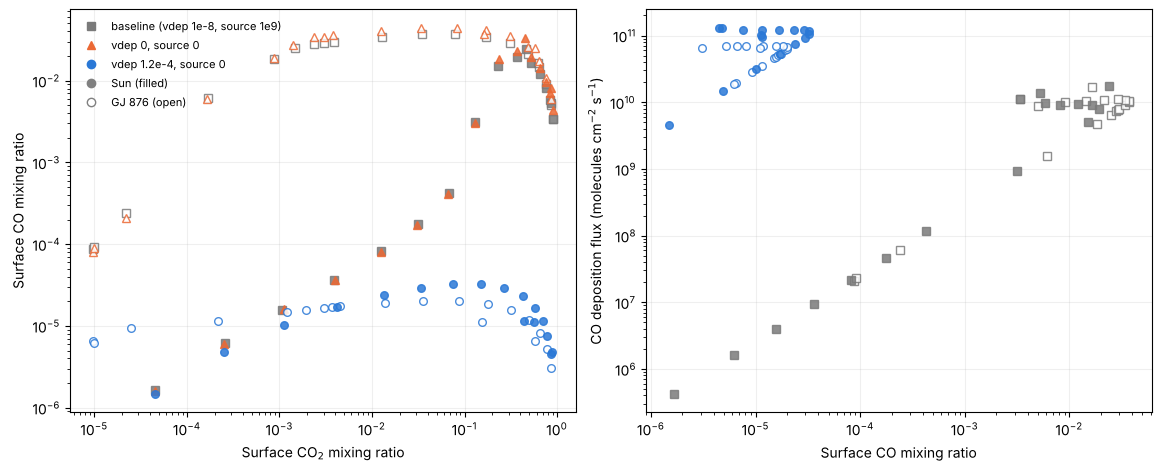

In [5]:
# trends: what controls CO, and how the ocean flux follows it
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6), constrained_layout=True)
for sc, s in SCEN.items():
    rr = [r for r in rows if r['scenario']==sc]
    for r in rr:
        for k, ax in enumerate(axs):
            y = r['CO'] if k == 0 else r['CO_dep_flux']; x = r['CO2'] if k == 0 else r['CO']
            if y <= 0: continue
            ax.plot(x, y, s['marker'], color=s['color'], mfc=s['color'] if r['star']=='Sun' else 'white', ms=5.5, alpha=.85)
axs[0].set_xlabel('Surface CO$_2$ mixing ratio'); axs[0].set_ylabel('Surface CO mixing ratio')
axs[1].set_xlabel('Surface CO mixing ratio'); axs[1].set_ylabel('CO deposition flux (molecules cm$^{-2}$ s$^{-1}$)')
for ax in axs: ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(alpha=.2)
axs[0].legend(handles=[Line2D([], [], color=s['color'], marker=s['marker'], ls='', label=s['label']) for s in SCEN.values()] +
              [Line2D([], [], color='gray', marker='o', ls='', mfc='gray', label='Sun (filled)'), Line2D([], [], color='gray', marker='o', ls='', mfc='white', label='GJ 876 (open)')], fontsize=8, frameon=False)
plt.show()

In [6]:
# table of results; also saved to co_diagnostics_table.csv
def eq(f): return f * 1e4 * SEC_YR / N_A                 # molecules/cm2/s -> mol/m2/yr
for r in rows:
    r['CO_dep_mol_m2_yr'] = eq(r['CO_dep_flux']); r['CO_dep_Tmol_yr_if_all_ocean'] = r['CO_dep_flux'] * AREA_CM2 * SEC_YR / N_A / 1e12
cols = ['star','scenario','S','T','at_288','coupling_converged','pCO2_bar','P_total_bar','CO2','CO','CH4','H2O','H2','O2','CO_dep_flux','CO_net_flux','CO_dep_mol_m2_yr','CO_dep_Tmol_yr_if_all_ocean','run_id']
with open('co_diagnostics_table.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(cols)
    for r in rows: w.writerow([f'{r[c]:.6g}' if isinstance(r[c], float) else r[c] for c in cols])
for star in ['Sun', 'GJ876']:
    print(f"\n{TITLE[star]}: CO deposition flux into the ocean, molecules/cm2/s (net in parentheses)")
    print(f"{'S':>8} | {'baseline':>20} | {'vdep 0':>14} | {'vdep 1.2e-4':>20} | {'1.2e-4 in Tmol/yr*':>18}")
    for S in sorted({r['S'] for r in rows if r['star']==star}, reverse=True):
        g = {r['scenario']: r for r in rows if r['star']==star and r['S']==S}
        f = lambda sc: f"{g[sc]['CO_dep_flux']:9.2e} ({g[sc]['CO_net_flux']:+9.2e})" if sc in g else 'n/a'
        print(f"{S:8.2f} | {f('baseline'):>20} | {f('vdep0'):>14} | {f('vdep1.2e-4'):>20} | {g['vdep1.2e-4']['CO_dep_Tmol_yr_if_all_ocean']:18.3g}")
print('\n* Tmol/yr = 1e12 mol/yr over the whole planet surface assumed to be ocean (upper bound).')


Sun at 3 Ga: CO deposition flux into the ocean, molecules/cm2/s (net in parentheses)
       S |             baseline |         vdep 0 |          vdep 1.2e-4 | 1.2e-4 in Tmol/yr*
 1400.00 |  4.24e+05 (-1.00e+09) |  0.00e+00 (+0.00e+00) |  4.53e+09 (+4.53e+09) |               1.21
 1331.25 |  1.60e+06 (-9.98e+08) |  0.00e+00 (+0.00e+00) |  1.49e+10 (+1.49e+10) |               3.98
 1262.50 |  4.04e+06 (-9.96e+08) |  0.00e+00 (+0.00e+00) |  3.13e+10 (+3.13e+10) |               8.35
 1193.75 |  9.34e+06 (-9.91e+08) |  0.00e+00 (+0.00e+00) |  5.22e+10 (+5.22e+10) |                 14
 1125.00 |  2.13e+07 (-9.79e+08) |  0.00e+00 (+0.00e+00) |  7.46e+10 (+7.46e+10) |               19.9
 1056.25 |  4.63e+07 (-9.54e+08) |  0.00e+00 (+0.00e+00) |  9.31e+10 (+9.31e+10) |               24.9
  987.50 |  1.16e+08 (-8.84e+08) |  0.00e+00 (+0.00e+00) |  1.07e+11 (+1.07e+11) |               28.6
  918.75 |  9.27e+08 (-7.35e+07) |  0.00e+00 (+0.00e+00) |  1.17e+11 (+1.17e+11) |               31.2
  850